# Importing Libraries

In [1]:
import numpy as np
import tensorflow as tf
# from keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing.image import ImageDataGenerator

import matplotlib.pyplot as plt

In [2]:
import os
print(os.getcwd())


c:\Users\saura\OneDrive\Desktop\agroalert\machineLearning\Plant_Disease_Prediction


In [3]:
import os
print(os.listdir())


['home_page.jpeg', 'main.py', 'New Plant Diseases Dataset(Augmented)', 'requirement.txt', 'Test_plant_disease.ipynb', 'trained_plant_disease_model.keras', 'training_hist.json', 'Train_plant_disease.ipynb']


Dataset Link: https://www.kaggle.com/datasets/vipoooool/new-plant-diseases-dataset

# Test set Image Processing

In [4]:
validation_set = tf.keras.utils.image_dataset_from_directory(
    "New Plant Diseases Dataset(Augmented)/valid",
    labels="inferred",
    label_mode="categorical",
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True
)

class_name = validation_set.class_names
print(class_name)


Found 17572 files belonging to 38 classes.
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Tw

# Loading Model

In [5]:
cnn = tf.keras.models.load_model('trained_plant_disease_model.keras')

In [8]:
pip install opencv-python


Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\saura\AppData\Local\Programs\Python\Python39\python.exe -m pip install --upgrade pip' command.


In [14]:
import cv2
print("OpenCV version:", cv2.__version__)


OpenCV version: 4.12.0


In [16]:
import os

print(os.listdir("New Plant Diseases Dataset(Augmented)/valid"))


['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___healthy', 'Corn_(maize)___Northern_Leaf_Blight', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___healthy', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___healthy', 'Potato___Late_blight', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___healthy', 'Strawberry___Leaf_scorch', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___healthy', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite',

#Visualising and Performing Prediction on Single image

Using image: 025b2b9a-0ec4-4132-96ac-7f2832d0db4a___FREC_C.Rust 3655_newGRR.JPG
Full path: New Plant Diseases Dataset(Augmented)/valid/Apple___Cedar_apple_rust\025b2b9a-0ec4-4132-96ac-7f2832d0db4a___FREC_C.Rust 3655_newGRR.JPG


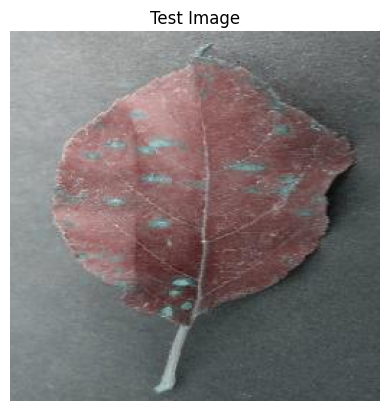

In [17]:
import os
import cv2
import matplotlib.pyplot as plt

# Folder path (CONFIRMED correct)
folder_path = r"New Plant Diseases Dataset(Augmented)/valid/Apple___Cedar_apple_rust"

# Pick first image automatically
image_name = os.listdir(folder_path)[0]
image_path = os.path.join(folder_path, image_name)

print("Using image:", image_name)
print("Full path:", image_path)

# Read image
img = cv2.imread(image_path)

if img is None:
    raise FileNotFoundError("Image could not be loaded. Path issue.")

# Convert BGR → RGB
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Show image
plt.imshow(img)
plt.title("Test Image")
plt.axis("off")
plt.show()


## Testing Model

In [18]:
image = tf.keras.preprocessing.image.load_img(image_path,target_size=(128,128))
input_arr = tf.keras.preprocessing.image.img_to_array(image)
input_arr = np.array([input_arr])  # Convert single image to a batch.
predictions = cnn.predict(input_arr)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 776ms/step


In [19]:
print(predictions)

[[1.28418208e-07 4.35651124e-08 9.99919534e-01 6.03640729e-08
  3.09851703e-06 1.86332599e-07 2.55898897e-07 1.53456483e-08
  1.19963079e-08 2.23059526e-08 2.56072337e-08 5.34730766e-08
  3.24518687e-08 1.37416425e-08 4.13732915e-09 3.66533257e-08
  5.79539062e-07 1.43584614e-07 6.63771438e-09 2.47384264e-06
  6.07380013e-09 4.35176606e-09 6.48025598e-05 6.28486475e-07
  1.54657641e-07 1.13878125e-08 8.86752616e-07 6.86777835e-09
  1.41616937e-07 2.77380138e-07 4.86499403e-07 2.19523088e-07
  4.07830100e-07 7.53033405e-08 2.12103345e-07 3.98383122e-07
  3.68728564e-07 4.22032099e-06]]


In [20]:
result_index = np.argmax(predictions) #Return index of max element
print(result_index)

2


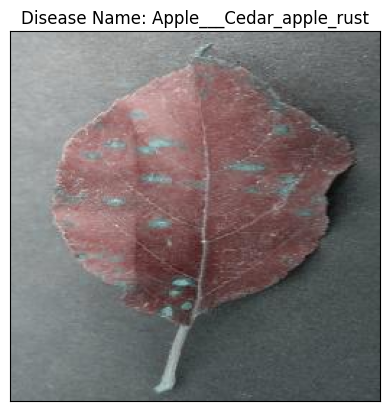

In [21]:
# Displaying the disease prediction
model_prediction = class_name[result_index]
plt.imshow(img)
plt.title(f"Disease Name: {model_prediction}")
plt.xticks([])
plt.yticks([])
plt.show()

In [23]:
cnn.save("trained_plant_disease_model.keras")
